In [4]:
## Code to read in the final models and assess variable contributions etc. ##

# Load in the required packages 

# Read in the packages to use
import numpy as np
import pandas as pd
import math
import datetime
import os
import pathlib
import matplotlib.pyplot as plt
import earthpy as et
import pickle
import random    

from sklearn.model_selection import GridSearchCV                      #for cross validation
from sklearn.feature_selection import RFE                             #for selecting features for the linear reg
from sklearn.model_selection import cross_val_score                   #for cross validation
from sklearn.model_selection import KFold                            
from sklearn.model_selection import GridSearchCV 
from sklearn.preprocessing import StandardScaler                      #for normalising the data
from sklearn.metrics import r2_score                                  #metrics for assessing model
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedShuffleSplit
import statsmodels.api as sm                                          #stats models to get linear reg p-values
from statsmodels.tools.eval_measures import rmse                      #calc rmse from stats models
import itertools                                                      #for calculating possible combinations of variables
from sklearn.preprocessing import PolynomialFeatures                  #for polynomial regression
from sklearn.pipeline import make_pipeline             
from xgboost import XGBRegressor
from scipy.stats import gaussian_kde
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import pvlib
import pytz

# load in the training data:
parent_folder = r"C:/Users/Sarah/Documents/Python_Scripts/DDL/Sensor_Network/Heat_model_Durham_Raleigh/"
train_data_path = os.path.join(parent_folder,"data/joined_data/ERA5_everyday_merged.csv")
data = pd.read_csv(train_data_path)

# sensor info - landcover type and shading scenario
sensor_info_path= r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\data\Installed Sensors_0.csv"
sensor_info = pd.read_csv(sensor_info_path)
landcover_shading_info = sensor_info.rename(columns = {'Sensor Serial Number':'Sensor_ID'})[['Sensor_ID','Landcover Type','Shade Type']]
data = data.merge(landcover_shading_info, on = 'Sensor_ID', how ='left')

### ----- Pre-clean -------
# fill 0 to categorical vars
# data.fillna(data.mean(),inplace = True)
# Create Cyclical Features for custom hour
#data.dropna(subset = ["Temperature"],inplace = True)
# Convert hours and minutes to total minutes since midnight
data['Hour'] = pd.to_datetime(data['Hour'], format='%H' )
data['Hour'] = data['Hour'].dt.hour
data['Total_Minutes'] = data['Hour'] * 60

# Create cyclical features using sine and cosine transformations
data['sin_time'] = np.sin(2 * np.pi * data['Total_Minutes'] / 1440)  # 1440 = total minutes in a day
data['cos_time'] = np.cos(2 * np.pi * data['Total_Minutes'] / 1440)

# get the zenith angle 
# convert to UTC for use in pvlib 
data['edt_datetime'] = pd.to_datetime(data['edt_datetime']).dt.tz_localize('US/Eastern')
data['utc_datetime'] = data['edt_datetime'].dt.tz_convert('UTC')

# calc solar positions
durham_lat = 35.99260
durham_lon = -78.89892

solpos = pvlib.solarposition.get_solarposition(
    time=data['utc_datetime'],
    latitude=durham_lat,
    longitude=durham_lon
)

# Add zenith angle to data 
data['zenith_angle'] = solpos['zenith'].values

# add in a temperature anomomly quantification to try as target variable (remove diurnal cycle)
data['temp_anom'] = data['Temperature'] - data['temperature_2m'] 
data['rh_anom'] = data['Relative_Humidity'] - data['relative_humidity_2m'] 


# add in the diurnal range -  this is so that the AT measurement standard error confidence intervals can be added into the main dataframe
# first find the mean daily hourly temps between the sensors
data_hour_means = data[['Temperature','Date','Hour']].groupby(['Date','Hour']).mean().reset_index()
# then group to find the min max
daily_max = data_hour_means[['Temperature','Date']].groupby('Date').max().reset_index().rename(columns ={'Temperature':'Max_Temp'})
daily_min = data_hour_means[['Temperature','Date']].groupby('Date').min().reset_index().rename(columns ={'Temperature':'Min_Temp'})
# substract min max to get the range
diurnal_ranges = daily_max.merge(daily_min, on = 'Date', how = 'left')
diurnal_ranges['Diurnal_Range'] = diurnal_ranges['Max_Temp']-diurnal_ranges['Min_Temp']
# add the diurnal range into the main data 
data = data.merge(diurnal_ranges[['Date','Diurnal_Range']], on = 'Date', how ='left')


### --- Define Model specs -----
# define Y and X
group_name = "Sensor_ID"
Y_name = "temp_anom"

# static variables first, then dynamic
#X_names_day =[ 'NDBI_2024SummerMosaic',
#          'NDVI_2024SummerMosaic', 'ESA_50',  
#         'nearest_motorway_thru_primary_dist','NDMI', 'Tree_DSM_SVF','Albedo_2024SummerMosaic',
#         'zenith_angle',#'cos_time', 
#              'surface_net_thermal_radiation_hourly','surface_solar_radiation_downwards_hourly',
#        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
 #       'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
 #       'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
#           ]
X_names_day =[ 'NDBI_2024SummerMosaic',
          'NDVI_2024SummerMosaic', 'ESA_50',  
         'nearest_motorway_thru_primary_dist','NDMI', 'Tree_DSM_SVF','Albedo_2024SummerMosaic',
         'zenith_angle',#'cos_time', 
              'surface_net_thermal_radiation_hourly','surface_solar_radiation_downwards_hourly',
        'surface_thermal_radiation_downwards_hourly',  'surface_solar_radiation_downwards_accumulation',
        'u_component_of_wind_10m',  'v_component_of_wind_10m', 'windspeed_10m', 
        'relative_humidity_2m', 'temperature_2m', 'total_precipitation_hourly',
           ]


X_names_day.append(group_name)
X_names_day.append('Hour') # save hour so can split by this later for analysis

X_names_night =['NDBI_2024SummerMosaic', 'NDVI_2024SummerMosaic', 'ESA_50', 'nearest_motorway_thru_primary_dist',  'zenith_angle',#'cos_time',  
     'surface_net_thermal_radiation_hourly', 'surface_thermal_radiation_downwards_hourly', 'Tree_DSM_SVF', 
     'surface_solar_radiation_downwards_accumulation', 'u_component_of_wind_10m', 'v_component_of_wind_10m',
     'windspeed_10m', 'relative_humidity_2m', 
     'temperature_2m', 'total_precipitation_hourly']

X_names_night.append(group_name)
X_names_night.append('Hour') # save hour so can split by this later for analysis


# when splitting, take the stratified sampling into account - want there is be all landcover & shading types in the test data
# Make composite strata = Landcover + ShadeType
data['strata'] = data['Landcover Type'].astype(str) + "_" + data['Shade Type'].astype(str)

# One strata label per sensor
sensor_strata = data.groupby('Sensor_ID')['strata'].first()

# Stratified split at the sensor level
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_sensors, test_sensors = next(sss.split(sensor_strata.index, sensor_strata.values))

train_sensor_ids = sensor_strata.index[train_sensors]
test_sensor_ids  = sensor_strata.index[test_sensors]

# modelling for incoming sol rad (daytime)
data_day = data[data['surface_solar_radiation_downwards_hourly'] > 1].copy().reset_index(drop = True)

# Apply split to full dataset
train_mask_day = data_day['Sensor_ID'].isin(train_sensor_ids)
test_mask_day  = data_day['Sensor_ID'].isin(test_sensor_ids)

y_day = data_day[Y_name].copy()
X_day = data_day[X_names_day].copy()

X_train_day, X_test_day = X_day[train_mask_day].copy(), X_day[test_mask_day].copy()
y_train_day, y_test_day = y_day[train_mask_day].copy(), y_day[test_mask_day].copy()

# copy datasets before removing hour/id for later analysis
train_day_w_hour = X_train_day.copy()
train_day_w_hour['Temperature'] = y_train_day
test_day_w_hour = X_test_day.copy()
test_day_w_hour['Temperature'] = y_test_day

# Drop ID/hour cols before modeling
X_train_day.drop(columns=[group_name, 'Hour'], inplace=True)
X_test_day.drop(columns=[group_name, 'Hour'], inplace=True)

#create normalised datasets
scaler = StandardScaler()
X_train_norm_day = pd.DataFrame(scaler.fit_transform(X_train_day.values), columns = X_train_day.columns) #fit and transform
X_test_norm_day = pd.DataFrame(scaler.transform(X_test_day.values), columns = X_test_day.columns) #transform only


# modelling for no incoming sol rad (nighttime)
data_night = data[data['surface_solar_radiation_downwards_hourly'] < 1].copy().reset_index(drop = True)
# Apply split to full dataset
train_mask_night = data_night['Sensor_ID'].isin(train_sensor_ids)
test_mask_night  = data_night['Sensor_ID'].isin(test_sensor_ids)

y_night = data_night[Y_name].copy()
X_night = data_night[X_names_night].copy()

X_train_night, X_test_night = X_night[train_mask_night].copy(), X_night[test_mask_night].copy()
y_train_night, y_test_night = y_night[train_mask_night].copy(), y_night[test_mask_night].copy()

# copy datasets before removing hour/id for later analysis
train_night_w_hour = X_train_night.copy()
train_night_w_hour['Temperature'] = y_train_night
test_night_w_hour = X_test_night.copy()
test_night_w_hour['Temperature'] = y_test_night

# Drop ID/hour cols before modeling
X_train_night.drop(columns=[group_name, 'Hour'], inplace=True)
X_test_night.drop(columns=[group_name, 'Hour'], inplace=True)

#create normalised datasets
scaler = StandardScaler()
X_train_norm_night = pd.DataFrame(scaler.fit_transform(X_train_night.values), columns = X_train_night.columns) #fit and transform
X_test_norm_night = pd.DataFrame(scaler.transform(X_test_night.values), columns = X_test_night.columns) #transform only

# function for getting the prediction interval
# y0 is the predicted value for an observation, y is actual values, y_pred is predicted values
def calc_pred_error(y, y_pred):                                       
    mse = mean_squared_error(y, y_pred) # calculate the mean squared error
    n = len(y_pred)
    mean_pred = np.mean(y_pred)
    y_pred_interval = []
    for y0 in y_pred:
        stderr = mse*(1+1/float(n)+(y0 - mean_pred)**2/np.sum((y_pred - mean_pred)**2))
        pred_interval = np.sqrt(stderr)
        y_pred_interval.append(pred_interval)
    return y_pred_interval


print("\nStrata distribution (per sensor):")
print("Full dataset:\n", sensor_strata.value_counts(normalize=True).round(2))
print("Train sensors:\n", sensor_strata.loc[train_sensor_ids].value_counts(normalize=True).round(2))
print("Test sensors:\n", sensor_strata.loc[test_sensor_ids].value_counts(normalize=True).round(2))

print(f"\nTrain sensors: {len(train_sensor_ids)}  Test sensors: {len(test_sensor_ids)}")

## daytime model 
day_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =883,max_depth = 8, learning_rate = 0.059,
                             subsample = 0.6,colsample_bytree = 0.61, min_child_weight =17,
                             gamma =  0.001,reg_alpha =0.0001 ,reg_lambda=80) 

day_xgb_model.fit(X_train_norm_day, y_train_day)

y_train_pred_day = day_xgb_model.predict(X_train_norm_day)
y_test_pred_day = day_xgb_model.predict(X_test_norm_day)

# Add city mean back to anomaly predictions
y_test_pred_full_day = y_test_pred_day + data_day[test_mask_day][ "temperature_2m"].values
y_train_pred_full_day = y_train_pred_day + data_day[train_mask_day][ "temperature_2m"].values
# Also get the true "full" temperatures
y_test_full_day = y_test_day + data_day[test_mask_day]["temperature_2m"].values
y_train_full_day = y_train_day + data_day[train_mask_day]["temperature_2m"].values


## nighttime model 
night_xgb_model = XGBRegressor(objective='reg:squarederror', random_state=42,
                             n_estimators =700,max_depth = 7, learning_rate = 0.2,
                             subsample = 0.9,colsample_bytree = 0.4, min_child_weight =26,
                             gamma =  0.014,reg_alpha =0.002 ,reg_lambda=57) 

night_xgb_model.fit(X_train_norm_night, y_train_night)

y_train_pred_night = night_xgb_model.predict(X_train_norm_night)
y_test_pred_night = night_xgb_model.predict(X_test_norm_night)

# Add city mean back to anomaly predictions
y_test_pred_full_night = y_test_pred_night + data_night[test_mask_night][ "temperature_2m"].values
y_train_pred_full_night = y_train_pred_night + data_night[train_mask_night][ "temperature_2m"].values
# Also get the true "full" temperatures
y_test_full_night = y_test_night + data_night[test_mask_night]["temperature_2m"].values
y_train_full_night = y_train_night + data_night[train_mask_night]["temperature_2m"].values

## Predictions for the entire 24hrs
y_test_pred_24hrs = np.concatenate([y_test_pred_full_day , y_test_pred_full_night])
y_train_pred_24hrs = np.concatenate([y_train_pred_full_day,y_train_pred_full_night])
y_test_24hrs = np.concatenate([y_test_full_day ,y_test_full_night])
y_train_24hrs = np.concatenate([y_train_full_day , y_train_full_night])


# add the data back into the dataframes 
data_night.loc[test_mask_night, 'Predicted_Temperature'] = y_test_pred_full_night
data_night.loc[train_mask_night, 'Predicted_Temperature'] = y_train_pred_full_night
data_day.loc[test_mask_day, 'Predicted_Temperature'] = y_test_pred_full_day
data_day.loc[train_mask_day, 'Predicted_Temperature'] = y_train_pred_full_day
data_full_24hrs = pd.concat([data_day, data_night])

C:\Users\Sarah\anaconda3\envs\durham_ml_analysis_env\Lib\site-packages\earthpy\__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_string



Strata distribution (per sensor):
Full dataset:
 strata
impervious_non-shaded    0.26
impervious_shaded        0.26
vegetation_shaded        0.26
vegetation_non-shaded    0.23
Name: proportion, dtype: float64
Train sensors:
 strata
impervious_shaded        0.26
impervious_non-shaded    0.26
vegetation_shaded        0.26
vegetation_non-shaded    0.22
Name: proportion, dtype: float64
Test sensors:
 strata
vegetation_shaded        0.25
impervious_shaded        0.25
vegetation_non-shaded    0.25
impervious_non-shaded    0.25
Name: proportion, dtype: float64

Train sensors: 27  Test sensors: 12


Training Metrics-- RMSE: 0.45203846147415505 R-square: 0.9901047365402609 MAE: 0.310033305762597 MBE: -0.000566217107799738 MPE (%): 0.03541210911258065
Test Metrics-- RMSE: 1.188038557066169 R-square: 0.9313434906068989 MAE: 0.8849149377742925 MBE: 0.1357794337681547 MPE (%): 0.666135236048323


Text(-0.08, 1, 'b')

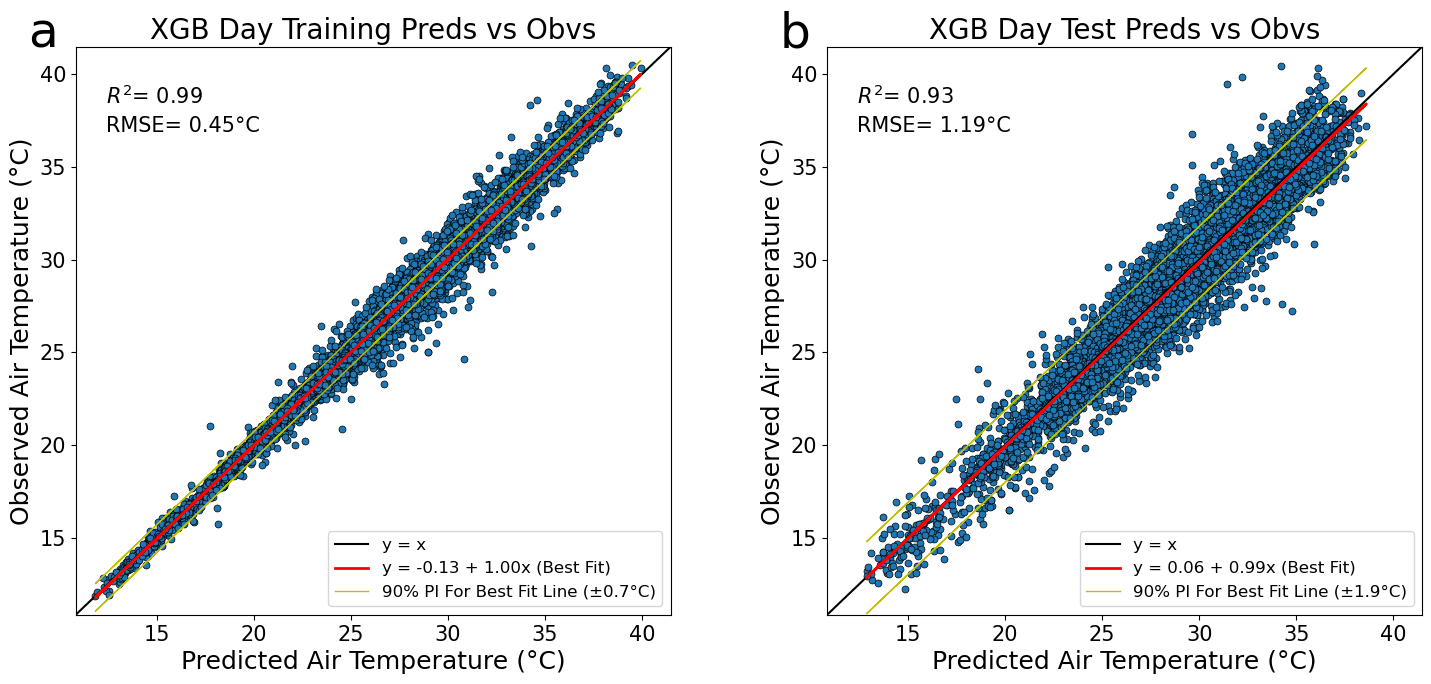

In [5]:
model_name = 'XGB Day'
y_test_pred_full = y_test_pred_full_day
y_train_pred_full = y_train_pred_full_day
y_test_full = y_test_full_day
y_train_full = y_train_full_day

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
#mbe
train_mbe = np.mean(y_train_pred_full - y_train_full)
#mean percentage error (mpe)
train_mpe = np.mean((y_train_pred_full - y_train_full) / y_train_full) * 100

print(
    'Training Metrics--',
    'RMSE:', train_rmse,
    'R-square:', train_r2,
    'MAE:', train_mae,
    'MBE:', train_mbe,
    'MPE (%):', train_mpe
)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
#mbe
test_mbe = np.mean(y_test_pred_full - y_test_full)
#mean percentage error (mpe)
test_mpe = np.mean((y_test_pred_full - y_test_full) / y_test_full) * 100

print(
    'Test Metrics--',
    'RMSE:', test_rmse,
    'R-square:', test_r2,
    'MAE:', test_mae,
    'MBE:', test_mbe,
    'MPE (%):', test_mpe
)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Air Temperature (\u00b0C)'
ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Preds vs Obvs'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


Training Metrics-- RMSE: 0.16562004757317117 R-square: 0.996977451896802 MAE: 0.12176784434738518
Test Metrics-- RMSE: 0.6978895246683975 R-square: 0.9486050861936715 MAE: 0.4932082860477367


Text(-0.08, 1, 'b')

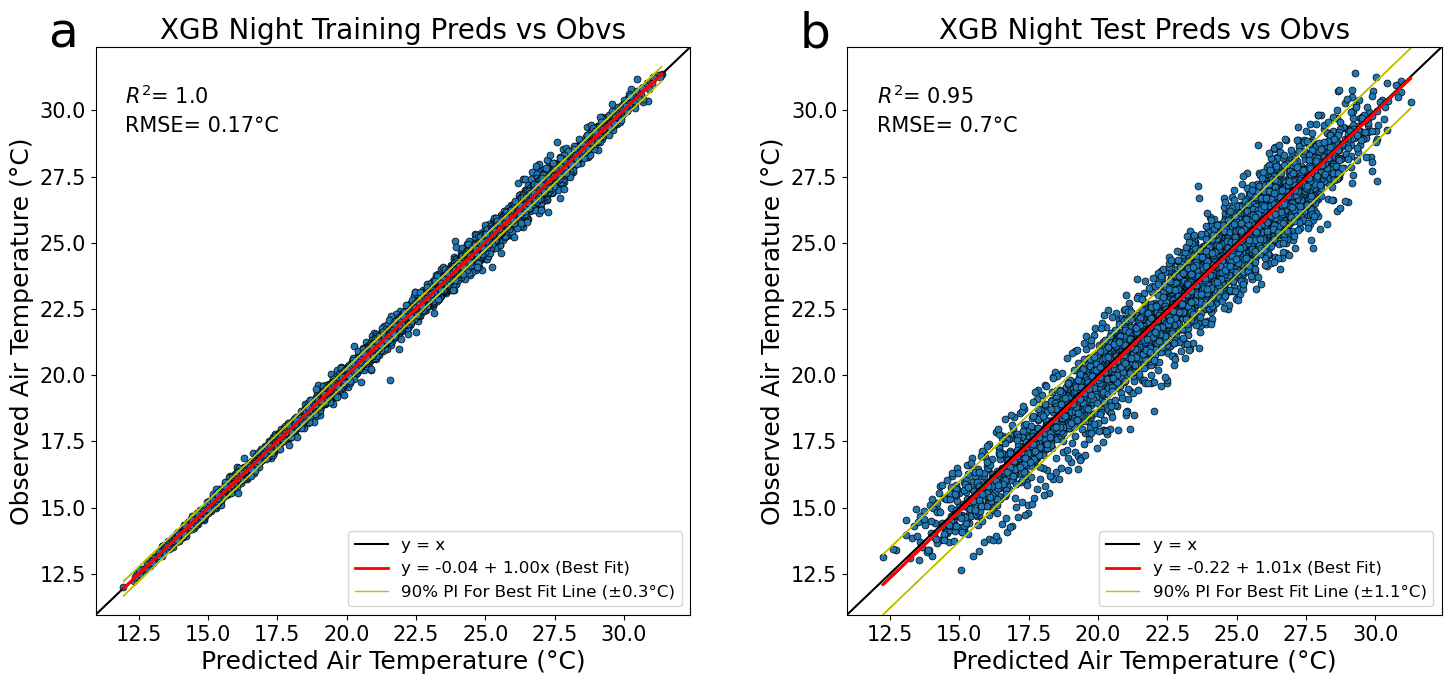

In [6]:
model_name = 'XGB Night'
y_test_pred_full = y_test_pred_full_night
y_train_pred_full = y_train_pred_full_night
y_test_full = y_test_full_night
y_train_full = y_train_full_night

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Air Temperature (\u00b0C)'
ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Preds vs Obvs'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params.iloc[0]
a = sm_model.params.iloc[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)


Training Metrics-- RMSE: 0.3665672521172933 R-square: 0.9936155035817097 MAE: 0.23557452691260286
Test Metrics-- RMSE: 1.021960153787925 R-square: 0.9507922243409761 MAE: 0.7293854109389942


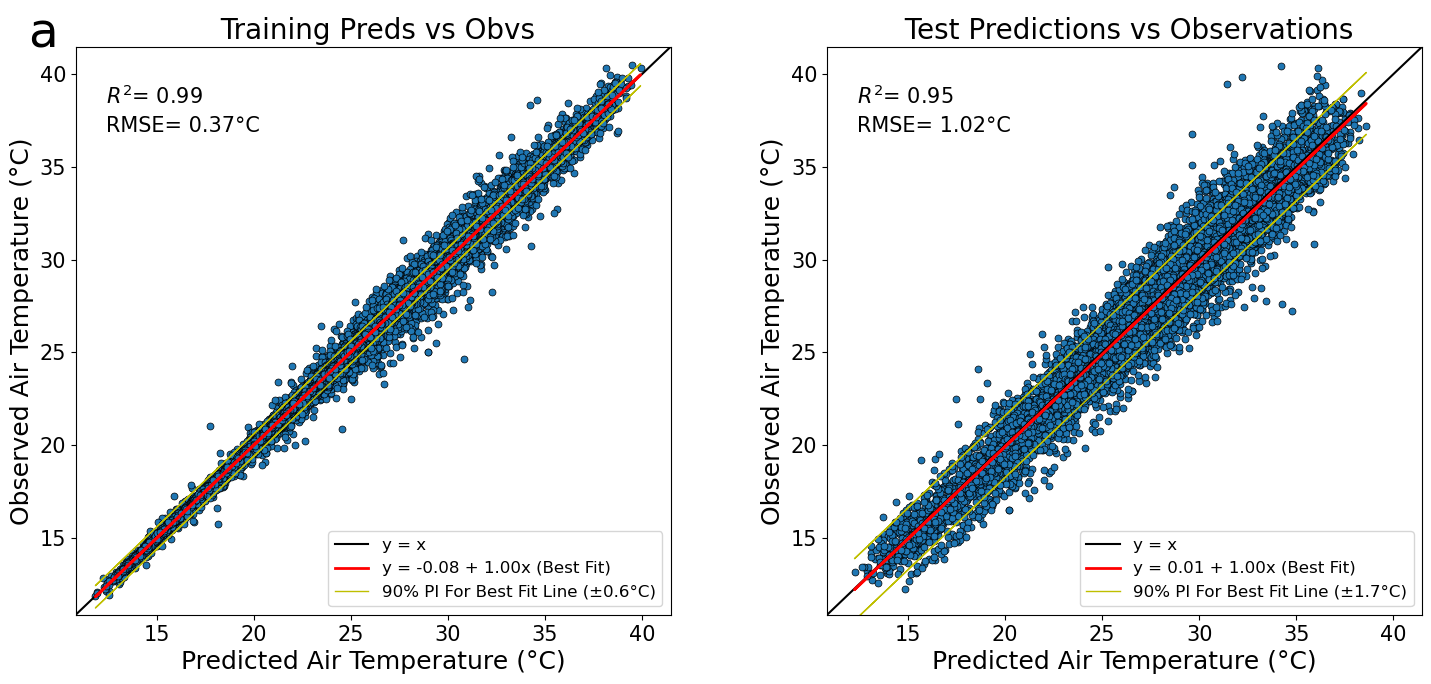

In [7]:
model_name = ''
y_test_pred_full = y_test_pred_24hrs
y_train_pred_full = y_train_pred_24hrs
y_test_full = y_test_24hrs
y_train_full = y_train_24hrs

######################################################
###### Performance Metrics for the training set ######
######################################################
#rmse
train_rmse = np.sqrt(mean_squared_error(y_train_full, y_train_pred_full))
#r-square~
train_r2 = r2_score(y_train_full, y_train_pred_full)
#mae
train_mae = mean_absolute_error(y_train_full, y_train_pred_full)
print('Training Metrics--', 'RMSE:', train_rmse, 'R-square:', train_r2, 'MAE:', train_mae)

#################################################
###### Performance Metrics for the test set #####
#################################################
#rmse
test_rmse = np.sqrt(mean_squared_error(y_test_full, y_test_pred_full))
#r-square
test_r2 = r2_score(y_test_full, y_test_pred_full)
#mae
test_mae = mean_absolute_error(y_test_full, y_test_pred_full)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)

# PLOTS: obvs vs predictions

#plt.rc('font', size=15)          # controls default text sizes
plt.rc('axes', titlesize=20)     # fontsize of the axes title
plt.rc('axes', labelsize=18)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=15)    # fontsize of the tick labels
plt.rc('ytick', labelsize=15)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize
plt.rc('figure', titlesize=20)  # fontsize of the figure title

# set plot labels
xlab = 'Predicted Air Temperature (\u00b0C)'
ylab = 'Observed Air Temperature (\u00b0C)'

# set the plot titles
train_title = '{} Training Preds vs Obvs'.format(model_name)
test_title = '{} Test Predictions vs Observations'.format(model_name)
    
# PLOTS: predictions vs obvs with line of best fit 

fig, axes = plt.subplots(1,2, figsize = (16, 8))
fig.tight_layout(pad=7.0)
# training data
axes[0].scatter( y_train_pred_full, y_train_full, s = 25, edgecolors='k', linewidths=0.5)
axes[0].set(title = train_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[0].set_xlim([axesmin, axesmax])
axes[0].set_ylim([axesmin, axesmax])
# x = y line
axes[0].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
# line of best fit
#p, V = np.polyfit(y_train_pred, y_train, 1, cov = True)
#a, b = p[0], p[1]

#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_train_full, sm.add_constant(y_train_pred_full)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_train_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()

axes[0].plot(y_train_pred_full, a*y_train_pred_full+b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

#axes[0].plot(y_train_pred, a*y_train_pred+b + np.std(a*y_train_pred+b), color='r', linestyle='--', 
#             linewidth=1, label = 'Fit std')
#axes[0].plot(y_train_pred, a*y_train_pred+b - np.std(a*y_train_pred+b), color='r', linestyle='--', linewidth=1)


axes[0].plot(y_train_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
             ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[0].plot(y_train_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1)


#text labels
axes[0].text(0.05, 0.9, '$R^2$= {}'.format(round(train_r2, 2)), fontsize=15, transform=axes[0].transAxes)
axes[0].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(train_rmse, 2)), fontsize=15, transform=axes[0].transAxes)
#axes[0].text(0.05, 0.02, 'y = ' + '{:.2f}'.format(b)+ 
#             ' + {:.2f}'.format(a) + 'x ', 
#             size=15,transform=axes[0].transAxes, color = 'r')

axes[0].legend(loc = 4)
# test data
axes[1].scatter(y_test_pred_full, y_test_full, s = 25, edgecolors='k', linewidths=0.5)
axes[1].set(title = test_title, 
         xlabel = xlab, ylabel = ylab)

axesmin = min(min(y_train_full), min(y_train_pred_full),min(y_test_full), min(y_test_pred_full)) - 1
axesmax = max(max(y_train_full), max(y_train_pred_full), max(y_test_full), max(y_test_pred_full)) + 1

axes[1].set_xlim([axesmin, axesmax])
axes[1].set_ylim([axesmin, axesmax])
axes[1].plot([axesmin, axesmax],[axesmin, axesmax], color = 'k', label = 'y = x')
#get the intercept/ slope of best fit line and prediction interval
sm_model = sm.OLS(y_test_full, sm.add_constant(y_test_pred_full)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(y_test_pred_full))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(y_test_full, y_test_pred_full)

#axes[1].scatter(y_test_pred, y_test_pred+pred_interval, s = 25, color = 'orange' , edgecolors='k', linewidths=0.5)

axes[1].plot(y_test_pred_full, a*y_test_pred_full +b, color='r', linestyle='-', linewidth=2, label = 'y = ' + '{:.2f}'.format(b)+ 
             ' + {:.2f}'.format(a) + 'x (Best Fit)')

axes[1].plot(y_test_pred_full , pred_interval_lower, color = 'y', linestyle='-', linewidth=1
            ,label = '90% PI For Best Fit Line ({}{:.1f}{})'.format(u'\u00B1',mean_PI,'\u00b0C'))
axes[1].plot(y_test_pred_full , pred_interval_upper, color = 'y', linestyle='-', linewidth=1) 


axes[1].legend(loc = 4)

axes[1].text(0.05, 0.9, '$R^2$= {}'.format(round(test_r2, 2)), fontsize=15, transform=axes[1].transAxes)
axes[1].text(0.05, 0.85, 'RMSE= {}\u00b0C'.format(round(test_rmse, 2)), fontsize=15, transform=axes[1].transAxes)

#add letters for figs
axes[0].text(-0.08, 1, 'a', fontsize=35, transform=axes[0].transAxes)
#axes[1].text(-0.08, 1, 'b', fontsize=35, transform=axes[1].transAxes)
plt.savefig('all_data.png',transparent=True)

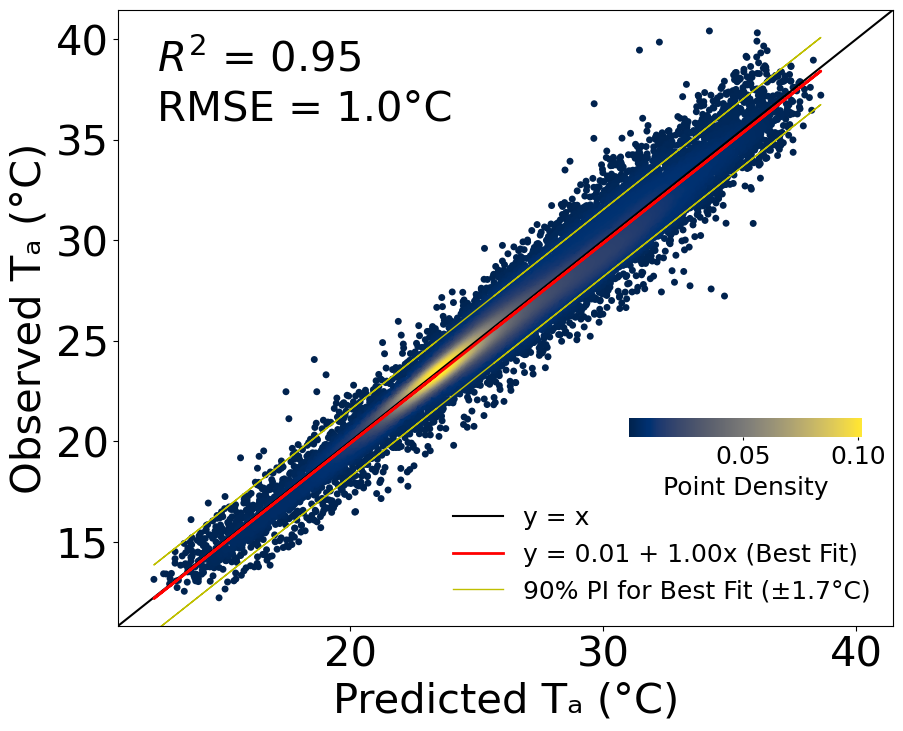

In [9]:
#  DENSITY SCATTER

xlab = 'Predicted Tₐ (\u00b0C)'
ylab = 'Observed Tₐ (\u00b0C)'

x = np.array(y_test_pred_full)
y = np.array(y_test_full)

xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, axes = plt.subplots(1, 1, figsize=(10, 8))

sc = axes.scatter(x, y, c=z, s=25, cmap='cividis', edgecolors='none')
axes.set_xlabel(xlab, fontsize=30)
axes.set_ylabel(ylab, fontsize=30)
axes.set_xlim([axesmin, axesmax])
axes.set_ylim([axesmin, axesmax])

axes.plot([axesmin, axesmax], [axesmin, axesmax], color='k', label='y = x')
axes.plot(
    y_test_pred_full, a*y_test_pred_full + b,
    color='r', linestyle='-', linewidth=2,
    label=f'y = {b:.2f} + {a:.2f}x (Best Fit)'
)
axes.plot(y_test_pred_full, pred_interval_lower, color='y', linestyle='-', linewidth=1,
          label=f'90% PI for Best Fit (±{mean_PI:.1f}°C)')
axes.plot(y_test_pred_full, pred_interval_upper, color='y', linestyle='-', linewidth=1)

axes.legend(loc=4, frameon =False, fontsize=18)
axes.text(0.05, 0.9, f'$R^2$ = {round(test_r2, 2)}', fontsize=30, transform=axes.transAxes)
axes.text(0.05, 0.82, f'RMSE = {round(test_rmse, 1)}°C', fontsize=30, transform=axes.transAxes)
axes.grid(False)
axes.tick_params(which='both', bottom=True, left=True, labelsize=30)

# Colorbar inside the plot
# Create small colorbar inset (width, height, x0, y0)
cax = inset_axes(axes, width="30%", height="3%", loc='upper right', 
                 bbox_to_anchor=(-0.03, -0.65, 1, 1), bbox_transform=axes.transAxes)
cbar = plt.colorbar(sc, cax=cax, orientation='horizontal')
cbar.set_label('Point Density', fontsize=18, labelpad=5)
cbar.ax.tick_params(labelsize=18, length=2)
cbar.outline.set_visible(False)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\AT_test_data_scatter_density_inset.png', 
            transparent=True, bbox_inches='tight', dpi = 1200)


In [11]:
########## Get test preds vs obvs for the HI #######################
 
# read in the rh data 
rh_scatter_data = pd.read_csv('rh_scatter_data.csv')

# calculate HI for the test predictions and observations 

at_y_test_pred_full = y_test_pred_full
at_y_test_full = y_test_full

rh_y_test_pred_full = rh_scatter_data.RH_Predicted
rh_y_test_full = rh_scatter_data.RH_Observed

def compute_heat_index(T, R):
    HI = 0.5 * (T + 61.0 + (T - 68.0) * 1.2 + R * 0.094) # steadman
    mask = HI >= 80 #use roth for heat index over 80
    HI_roth = (-42.379 + 2.04901523 * T + 10.14333127 * R
               - 0.22475541 * T * R - 6.83783e-3 * T**2
               - 5.481717e-2 * R**2 + 1.22874e-3 * T**2 * R
               + 8.5282e-4 * T * R**2 - 1.99e-6 * T**2 * R**2)
    HI = np.where(mask, HI_roth, HI)
    # adjustments, in line with NOAA
    adj1_mask = (R < 13) & (T >= 80) & (T <= 112)
    adj1 = ((13 - R) / 4.0) * np.sqrt((17 - np.abs(T - 95.0)) / 17.0)
    HI = np.where(adj1_mask, HI - adj1, HI)

    adj2_mask = (R > 85) & (T >= 80) & (T <= 87)
    adj2 = ((R - 85) / 10.0) * ((87 - T) / 5.0)
    HI = np.where(adj2_mask, HI + adj2, HI)
    return HI

def F_to_C(F):
    return (F - 32.0) * 5.0 / 9.0
    
# change the at into fahrenheit for the heat index calculation 
at_y_test_pred_full_F = at_y_test_pred_full * 9.0 / 5.0 + 32.0
at_y_test_full_F = at_y_test_full * 9.0 / 5.0 + 32.0

# compute the HI in degF   
hi_y_test_pred_full_F = compute_heat_index(at_y_test_pred_full_F, rh_y_test_pred_full)    
hi_y_test_full_F = compute_heat_index(at_y_test_full_F, rh_y_test_full)   

hi_y_test_pred_full_C = F_to_C(hi_y_test_pred_full_F)
hi_y_test_full_C = F_to_C(hi_y_test_full_F)

C:\Users\Sarah\AppData\Local\Temp\ipykernel_11508\181924582.py:24: RuntimeWarning: invalid value encountered in sqrt
  adj1 = ((13 - R) / 4.0) * np.sqrt((17 - np.abs(T - 95.0)) / 17.0)


Test Metrics-- RMSE: 1.479262160377993 R-square: 0.9448528874384696 MAE: 1.0124311987272854


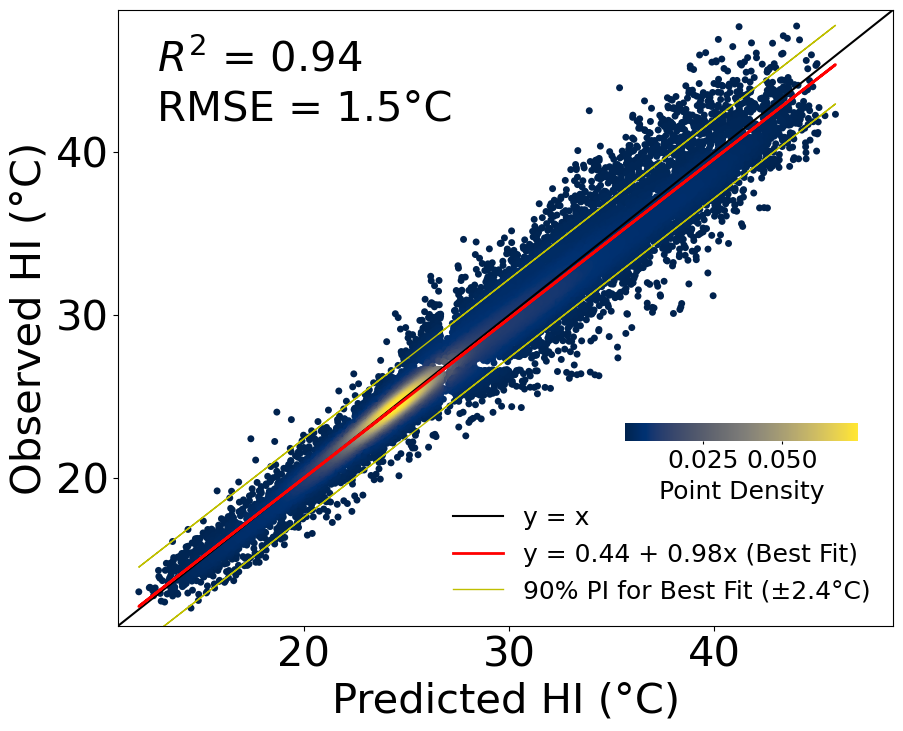

In [12]:
plt.rcParams.update({
    'font.size': 22,
    'axes.labelsize': 30,
    'axes.titlesize': 30,
    'xtick.labelsize': 30,
    'ytick.labelsize': 30,
    'legend.fontsize': 18
})

#rmse
test_rmse = np.sqrt(mean_squared_error(hi_y_test_full_C, hi_y_test_pred_full_C))
#r-square
test_r2 = r2_score(hi_y_test_full_C, hi_y_test_pred_full_C)
#mae
test_mae = mean_absolute_error(hi_y_test_full_C, hi_y_test_pred_full_C)
print('Test Metrics--', 'RMSE:', test_rmse, 'R-square:', test_r2, 'MAE:', test_mae)


x = np.array(hi_y_test_pred_full_C)
y = np.array(hi_y_test_full_C)

xlab = 'Predicted HI (\u00b0C)'
ylab = 'Observed HI (\u00b0C)'

axesmin = min(min(hi_y_test_pred_full_C), min(hi_y_test_full_C)) - 1
axesmax = max(max(hi_y_test_pred_full_C), max(hi_y_test_full_C)) + 1

sm_model = sm.OLS(hi_y_test_full_C, sm.add_constant(hi_y_test_pred_full_C)).fit()
b = sm_model.params[0]
a = sm_model.params[1]
sm_pred = sm_model.get_prediction(sm.add_constant(hi_y_test_pred_full_C))\
                  .summary_frame(alpha=0.1)

pred_interval_lower = sm_pred.obs_ci_lower.values
pred_interval_upper = sm_pred.obs_ci_upper.values
mean_PI = ((pred_interval_upper - pred_interval_lower)/2).mean()
pred_interval = calc_pred_error(hi_y_test_full_C, hi_y_test_pred_full_C)


xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)
idx = z.argsort()
x, y, z = x[idx], y[idx], z[idx]

fig, axes = plt.subplots(1, 1, figsize=(10, 8))

sc = axes.scatter(x, y, c=z, s=25, cmap='cividis', edgecolors='none')
axes.set(xlabel=xlab, ylabel=ylab)
axes.set_xlim([axesmin, axesmax])
axes.set_ylim([axesmin, axesmax])

axes.plot([axesmin, axesmax], [axesmin, axesmax], color='k', label='y = x')
axes.plot(
    hi_y_test_pred_full_C, a*hi_y_test_pred_full_C + b,
    color='r', linestyle='-', linewidth=2,
    label=f'y = {b:.2f} + {a:.2f}x (Best Fit)'
)
axes.plot(hi_y_test_pred_full_C, pred_interval_lower, color='y', linestyle='-', linewidth=1,
          label=f'90% PI for Best Fit (±{mean_PI:.1f}°C)')
axes.plot(hi_y_test_pred_full_C, pred_interval_upper, color='y', linestyle='-', linewidth=1)

axes.legend(loc=4, frameon =False)
axes.text(0.05, 0.9, f'$R^2$ = {round(test_r2, 2)}', fontsize=30, transform=axes.transAxes)
axes.text(0.05, 0.82, f'RMSE = {round(test_rmse, 1)}°C', fontsize=30, transform=axes.transAxes)
axes.grid(False)
axes.tick_params(which='both', bottom=True, left=True)

# Colorbar inside the plot
# Create small colorbar inset (width, height, x0, y0)
cax = inset_axes(axes, width="30%", height="3%", loc='upper right', 
                 bbox_to_anchor=(-0.03, -0.65, 1, 1), bbox_transform=axes.transAxes)
cbar = plt.colorbar(sc, cax=cax, orientation='horizontal')
cbar.set_label('Point Density', fontsize=18, labelpad=5)
cbar.ax.tick_params(labelsize=18, length=2)
cbar.outline.set_visible(False)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\HI_test_data_scatter_density_inset.png', 
            transparent=True, bbox_inches='tight', dpi = 1200)


In [15]:
import seaborn as sns

In [16]:
# Get feature importances
importances = day_xgb_model.feature_importances_

# Put into a dataframe for readability
feat_importances = pd.DataFrame({
    "Feature": X_train_norm_day.columns,
    "Importance_AT_Day": importances
}).sort_values(by="Importance_AT_Day", ascending=False)

print(feat_importances)

                                           Feature  Importance_AT_Day
4                                             NDMI           0.099436
11  surface_solar_radiation_downwards_accumulation           0.094960
15                            relative_humidity_2m           0.079289
10      surface_thermal_radiation_downwards_hourly           0.066394
17                      total_precipitation_hourly           0.065018
16                                  temperature_2m           0.061784
0                            NDBI_2024SummerMosaic           0.057928
6                          Albedo_2024SummerMosaic           0.055988
8             surface_net_thermal_radiation_hourly           0.054927
7                                     zenith_angle           0.049929
13                         v_component_of_wind_10m           0.046846
5                                     Tree_DSM_SVF           0.046362
12                         u_component_of_wind_10m           0.043500
9         surface_so

C:\Users\Sarah\AppData\Local\Temp\ipykernel_11508\2340638848.py:13: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


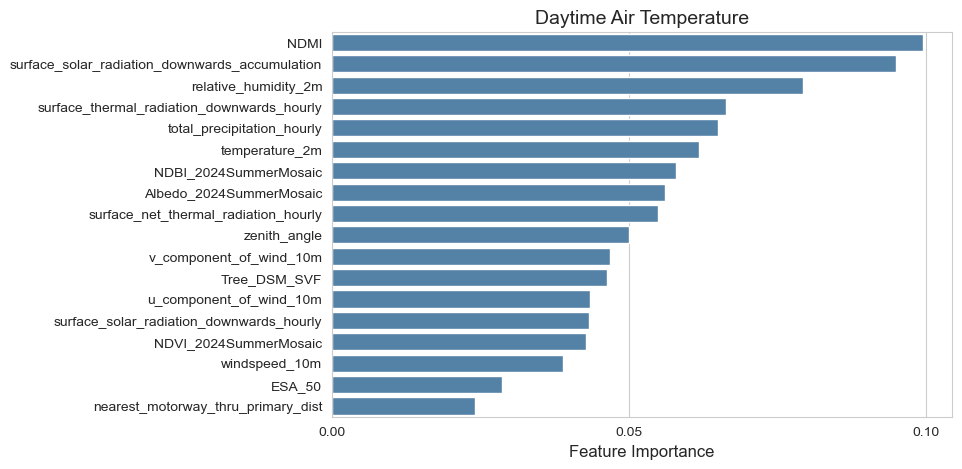

In [17]:
plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
sns.barplot(
    data=feat_importances,
    y="Feature",                 
    x="Importance_AT_Day",
    color="steelblue"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")                 
plt.title("Daytime Air Temperature", fontsize=14)#, weight='bold')
plt.tight_layout()

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.savefig('results/at_day_rel_imp.png',transparent=True)

C:\Users\Sarah\AppData\Local\Temp\ipykernel_11508\675193956.py:24: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


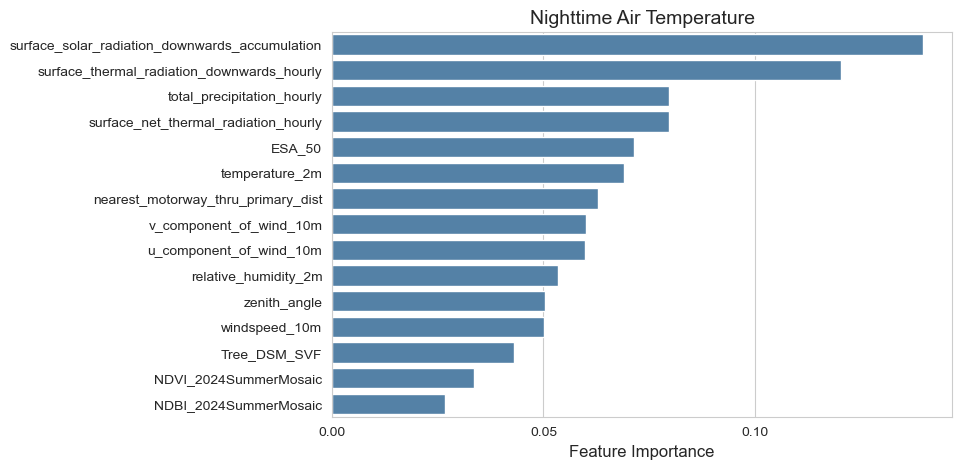

In [18]:
# Get feature importances
importances = night_xgb_model.feature_importances_

# Put into a dataframe for readability
feat_importances_AT_night = pd.DataFrame({
    "Feature": X_train_norm_night.columns,
    "Importance_AT_Night": importances
}).sort_values(by="Importance_AT_Night", ascending=False)

#print(feat_importances)

plt.figure(figsize=(8, 5))
sns.set_style("whitegrid")
sns.barplot(
    data=feat_importances_AT_night,
    y="Feature",                 
    x="Importance_AT_Night",
    color="steelblue"
)

plt.xlabel("Feature Importance", fontsize=12)
plt.ylabel("")                 
plt.title("Nighttime Air Temperature", fontsize=14)#, weight='bold')
plt.tight_layout()

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.savefig('results/at_night_rel_imp.png',transparent=True)

In [19]:
feat_importances

,Feature,Importance_AT_Day
4,NDMI,0.099436
11,surface_solar_radiation_downwards_accumulation,0.094960
15,relative_humidity_2m,0.079289
10,surface_thermal_radiation_downwards_hourly,0.066394
17,total_precipitation_hourly,0.065018
16,temperature_2m,0.061784
0,NDBI_2024SummerMosaic,0.057928
6,Albedo_2024SummerMosaic,0.055988
8,surface_net_thermal_radiation_hourly,0.054927
7,zenith_angle,0.049929


In [20]:
feat_importances = feat_importances.merge(feat_importances_AT_night, on = 'Feature', how = 'left')
feat_importances_RH_day = pd.read_csv('feat_importances_RH_day.csv')
feat_importances_RH_night = pd.read_csv('feat_importances_RH_night.csv')
feat_importances = feat_importances.merge(feat_importances_RH_day, on = 'Feature', how = 'left').merge(feat_importances_RH_night, on = 'Feature', how = 'left')

In [21]:
# Changing the names for consistency/ length for the feature importance plots  
variable_name_dict = {'NDBI_2024SummerMosaic':'NDBI',
          'NDVI_2024SummerMosaic':'NDVI', 'ESA_50':'Is_Builtup',  
         'nearest_motorway_thru_primary_dist':'Major_road_distance','NDMI':'NDMI', 'Tree_DSM_SVF':'Tree_SVF',
            'Albedo_2024SummerMosaic':'Albedo',
         'zenith_angle':'Zenith_angle',
              'surface_net_thermal_radiation_hourly':'Net_thermal','surface_solar_radiation_downwards_hourly':'DW_solar',
        'surface_thermal_radiation_downwards_hourly':'DW_thermal',  'surface_solar_radiation_downwards_accumulation':'DW_solar_acc',
        'u_component_of_wind_10m':'U_wind',  'v_component_of_wind_10m':'V_wind', 'windspeed_10m':'Windspeed', 
        'relative_humidity_2m':'City_RH', 'temperature_2m':'City_AT', 'total_precipitation_hourly':'TP'}

feat_importances['Feature'] = feat_importances['Feature'].replace(variable_name_dict)

In [22]:
feat_importances

,Feature,Importance_AT_Day,Importance_AT_Night,Importance_RH_Day,Importance_RH_Night
0,NDMI,0.099436,NaN,0.070359,0.030424
1,DW_solar_acc,0.094960,0.139683,0.113973,0.159589
2,City_RH,0.079289,0.053453,0.083113,0.241637
3,DW_thermal,0.066394,0.120419,0.077473,0.075417
4,TP,0.065018,0.079730,0.071190,0.072291
5,City_AT,0.061784,0.068988,0.057768,0.038095
6,NDBI,0.057928,0.026592,0.081000,0.035387
7,Albedo,0.055988,NaN,0.030532,NaN
8,Net_thermal,0.054927,0.079669,0.077686,0.048139
9,Zenith_angle,0.049929,0.050344,0.053006,0.034583


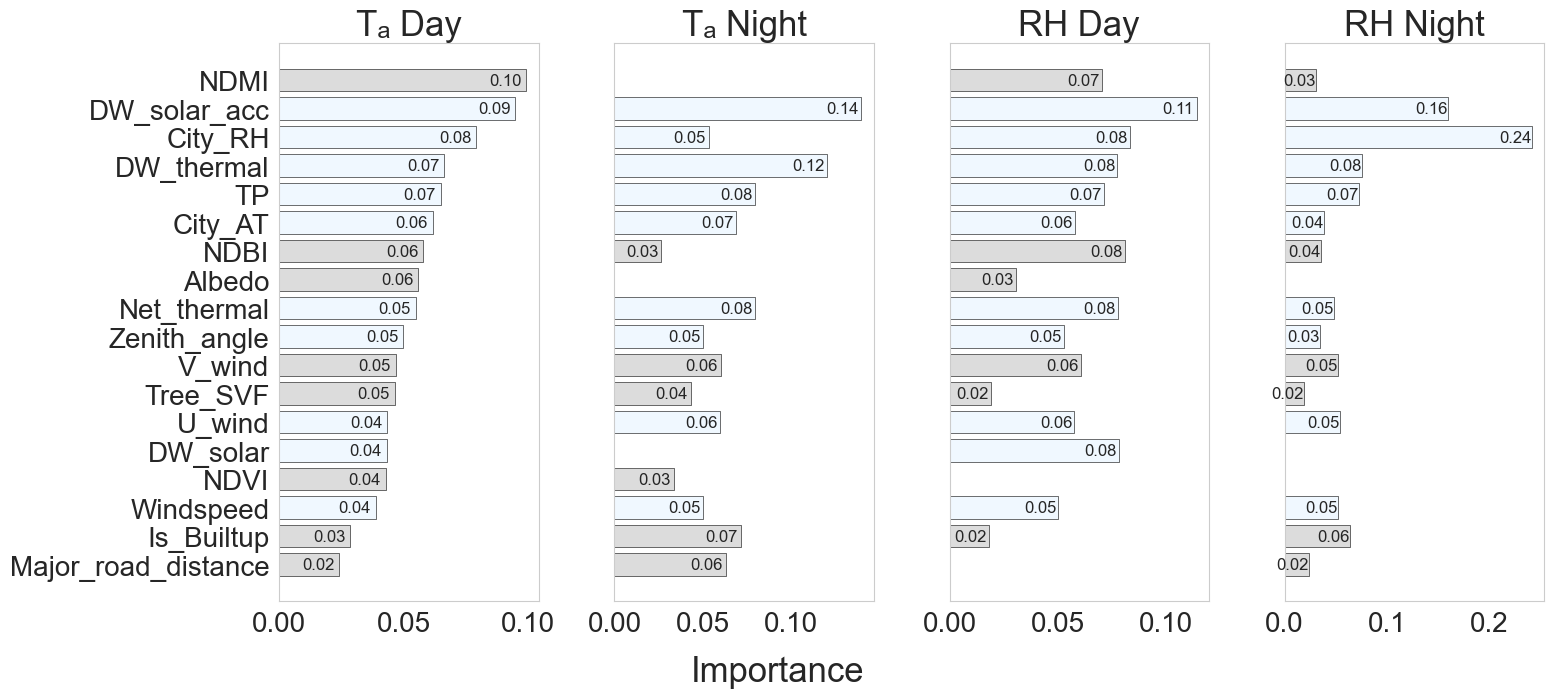

In [45]:
# Columns and titles
cols = ['Importance_AT_Day', 'Importance_AT_Night', 'Importance_RH_Day', 'Importance_RH_Night']
titles = ['Tₐ Day', 'Tₐ Night', 'RH Day', 'RH Night']

dynamic_vars = ['DW_solar_acc','City_RH','DW_thermal','TP','City_AT','Net_thermal','Zenith_angle','U_wind','DW_solar','Windspeed']
#feat_order = feat_importances.sort_values('Importance_AT_Day', ascending=True)
#panel_colors = ['#5DADE2', '#48C9B0', '#F4D03F', '#EC7063']

# Create 4 horizontal bar charts
fig, axes = plt.subplots(1, 4, figsize=(16, 8), sharey=True)

for i, (col, title) in enumerate(zip(cols, titles)):
    axes[i].grid(False)
    color = ['aliceblue' if f in dynamic_vars else 'gainsboro' for f in feat_importances['Feature']]# blue for dynamic vars, grey for static
    
    axes[i].barh(feat_importances['Feature'], feat_importances[col],color = color,edgecolor='black', linewidth=0.4  ) #, color=panel_colors[i])
    axes[i].set_title(title, fontsize=25)
    if i == 0:
        axes[i].set_ylabel('', fontsize=25)
    
    
    #axes[i].set_xlabel('Importance', fontsize=12)
    
    
    for bar in axes[i].patches:
        width = bar.get_width()
        if col == 'Importance_AT_Day':
            dist_from_edge = 0.015
        elif col == 'Importance_AT_Night':
            dist_from_edge = 0.02
        elif col == 'Importance_RH_Day':
            dist_from_edge = 0.016
        else:
            dist_from_edge = 0.032
        
        axes[i].text(width - dist_from_edge, bar.get_y() + bar.get_height()/2,
                     f'{width:.2f}', va='center', fontsize=12)

        axes[i].tick_params(axis='both', labelsize=20)
        #axes[i].tick_params(axis='y', labelsize=16)
        #axes[i].tick_params(axis='x', labelsize=14)

axes[0].invert_yaxis()  # to order by most important feautre of AT day

fig.supxlabel('Importance', fontsize=25, y = 0.06)
#fig.suptitle('Feature Importances', fontsize=16)

plt.tight_layout(rect=[0, 0, 1, 0.95])

#plt.savefig('all_models_variable_importances.png', transparent=True, bbox_inches='tight', dpi = 1200)

plt.savefig(r'C:\Users\Sarah\OneDrive - University of North Carolina at Chapel Hill\Documents\DDL\Science_Projects\Sensors\ML_model_paper\all_models_variable_importances.png', 
            format='png', dpi=1200, bbox_inches='tight')

In [36]:
# add in the confidence intervals for the measurement error 
# read in the ci parameters to add in measurment errors 
at_ci_params_filepath = r"C:\Users\Sarah\Documents\Python_Scripts\DDL\Sensor_Network\Heat_model_Durham_Raleigh\src\model_training\SB\AT_ci_params.csv"

at_ci_params = pd.read_csv(at_ci_params_filepath)

# equation for calculating the upper confidence interval for the AT sensor error
def upper_ci(slope, intercept, x_mean, s_err, Sxx, n, t_crit, x_vals):
    x = np.asarray(x_vals)
    ci_width = t_crit * s_err * np.sqrt(1/n + (x - x_mean)**2 / Sxx)
    return slope * x + intercept + ci_width

# Extract CI parameters
day_ci_params = at_ci_params[at_ci_params.Day_Night == 'Day']
slope_day = day_ci_params["slope"].values[0]
intercept_day = at_ci_params["intercept"].values[0]
x_mean_day = at_ci_params["x_mean"].values[0]
s_err_day = at_ci_params["s_err"].values[0]
Sxx_day = at_ci_params["Sxx"].values[0]
n_day = at_ci_params["n"].values[0]
t_crit_day = at_ci_params["t_crit"].values[0]

night_ci_params = at_ci_params[at_ci_params.Day_Night == 'Night']
slope_night = night_ci_params["slope"].values[0]
intercept_night = night_ci_params["intercept"].values[0]
x_mean_night = night_ci_params["x_mean"].values[0]
s_err_night = night_ci_params["s_err"].values[0]
Sxx_night = night_ci_params["Sxx"].values[0]
n_night = night_ci_params["n"].values[0]
t_crit_night = night_ci_params["t_crit"].values[0]

# calculate the day and night measurement error, 95% upper confidence interval  
data_day['AT_Measurement_CI'] = upper_ci(slope_day, intercept_day, x_mean_day, s_err_day, Sxx_day, n_day, t_crit_day, data_day['Diurnal_Range'])
data_night['AT_Measurement_CI'] = upper_ci(slope_night, intercept_night, x_mean_night, s_err_night, Sxx_night, n_night, t_crit_night, data_night['Diurnal_Range'])

# the RH error is set as 95th percentile of standard error between sensors in calibration experiments 
#Day RH 95th percentile std error 0.36235253201311085
#Night RH 95th percentile std error 0.257524304052384

day_rh_measurement_err = 0.36235
night_rh_measurement_err = 0.2575

data_day['RH_Measurement_CI'] = day_rh_measurement_err
data_night['RH_Measurement_CI'] = night_rh_measurement_err

In [37]:
############### Hourly performance ####################
data_all_w_predicted = pd.concat([data_day, data_night])
data_all_w_predicted = data_all_w_predicted[data_all_w_predicted.Sensor_ID.isin(test_sensor_ids)]

In [38]:
data_all_w_predicted

,Temperature,Relative_Humidity,Date,Hour,Sensor_ID,x,y,Albedo_2024SummerMosaic,CDL_org,CDL_121,...,cos_time,utc_datetime,zenith_angle,temp_anom,rh_anom,Diurnal_Range,strata,Predicted_Temperature,AT_Measurement_CI,RH_Measurement_CI
5368,24.083333,92.716667,2024-07-01,7,2558026,-78.855844,35.881735,0.188652,121,1,...,-2.588190e-01,2024-07-01 11:00:00+00:00,80.410078,1.247095,0.780211,7.918254,vegetation_non-shaded,23.407023,0.034068,0.36235
5369,22.111111,85.066667,2024-07-01,8,2558026,-78.855844,35.881735,0.188652,121,1,...,-5.000000e-01,2024-07-01 12:00:00+00:00,68.857161,0.230712,3.047042,7.918254,vegetation_non-shaded,21.376985,0.034068,0.36235
5370,21.148148,83.266667,2024-07-01,9,2558026,-78.855844,35.881735,0.188652,121,1,...,-7.071068e-01,2024-07-01 13:00:00+00:00,56.913466,-0.895674,18.770371,7.918254,vegetation_non-shaded,21.504681,0.034068,0.36235
5371,21.842593,69.500000,2024-07-01,10,2558026,-78.855844,35.881735,0.188652,121,1,...,-8.660254e-01,2024-07-01 14:00:00+00:00,44.797136,-1.339230,15.327931,7.918254,vegetation_non-shaded,21.756961,0.034068,0.36235
5372,24.064815,54.183333,2024-07-01,11,2558026,-78.855844,35.881735,0.188652,121,1,...,-9.659258e-01,2024-07-01 15:00:00+00:00,32.792268,-0.428173,6.781091,7.918254,vegetation_non-shaded,22.888937,0.034068,0.36235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22189,21.768519,99.233333,2024-08-31,6,2974347,-78.844527,36.011712,0.161167,124,0,...,6.123234e-17,2024-08-31 10:00:00+00:00,100.032245,-0.082710,0.697729,9.276666,impervious_shaded,22.110585,0.010554,0.25750
22190,21.620370,99.233333,2024-08-31,7,2974347,-78.844527,36.011712,0.161167,124,0,...,-2.588190e-01,2024-08-31 11:00:00+00:00,88.252829,-0.127959,0.278893,9.276666,impervious_shaded,22.065801,0.010554,0.25750
22191,25.805556,88.500000,2024-08-31,21,2974347,-78.844527,36.011712,0.161167,124,0,...,7.071068e-01,2024-09-01 01:00:00+00:00,105.606812,-0.351516,5.141037,9.276666,impervious_shaded,27.079228,0.010554,0.25750
22192,25.435185,89.633333,2024-08-31,22,2974347,-78.844527,36.011712,0.161167,124,0,...,8.660254e-01,2024-09-01 02:00:00+00:00,116.319336,-0.230842,5.969673,9.276666,impervious_shaded,26.102597,0.010554,0.25750


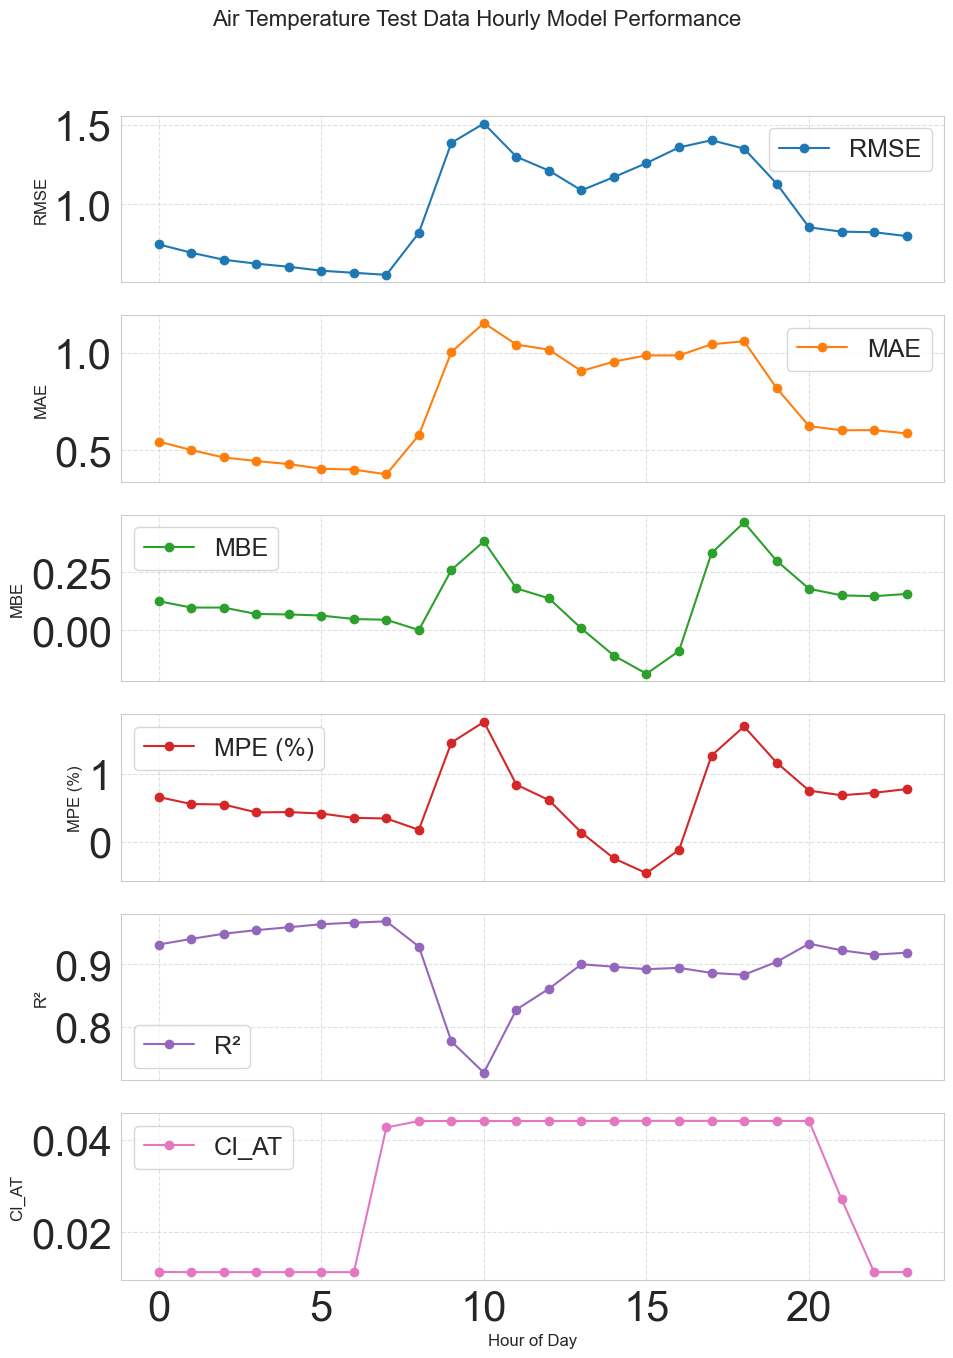

In [39]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

def calc_metrics(obs, pred):
    rmse = np.sqrt(mean_squared_error(obs, pred))
    mae = mean_absolute_error(obs, pred)
    mbe = np.mean(pred - obs)
    mpe = np.mean((pred - obs) / obs) * 100     # %
    r2  = r2_score(obs, pred)
    return rmse, mae, mbe, mpe, r2

# --- Compute hourly metrics ---
hourly_stats = []
for hour, group in data_all_w_predicted.groupby('Hour'):
    rmse, mae, mbe, mpe, r2 = calc_metrics(group['Temperature'], group['Predicted_Temperature'])
    ci_at = group['AT_Measurement_CI'].mean()
   
    
    hourly_stats.append({
        'Hour': hour,
        'RMSE': rmse,
        'MAE': mae,
        'MBE': mbe,
        'MPE (%)': mpe,
        'R²': r2,
        'CI_AT':ci_at,
        
    })

hourly_stats_df = pd.DataFrame(hourly_stats).sort_values('Hour')
hourly_stats_df.to_csv('results/hourly_plots/AT_hourly_stats.csv', index = None)
#print(hourly_stats_df)

# --- Create subplots: one subplot for each metric ---
metrics = ['RMSE', 'MAE', 'MBE', 'MPE (%)', 'R²','CI_AT']
colors  = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple','tab:pink']

fig, axes = plt.subplots(len(metrics), 1, figsize=(10, 14), sharex=True)

for ax, metric, color in zip(axes, metrics, colors):
    ax.plot(hourly_stats_df['Hour'], hourly_stats_df[metric],
            marker='o', color=color, label=metric)
    ax.set_ylabel(metric, fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='best')

axes[-1].set_xlabel('Hour of Day', fontsize=12)
fig.suptitle('Air Temperature Test Data Hourly Model Performance', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [44]:
# Daytime RMSE 
print('08:00 - 19:00 Ta RMSE', hourly_stats_df[(hourly_stats_df.Hour >=8)&(hourly_stats_df.Hour <=19)].RMSE.mean())

#Nighttime RMSE 
print('20:00 - 07:00 Ta RMSE', hourly_stats_df[(hourly_stats_df.Hour <=7)|(hourly_stats_df.Hour >=20)].RMSE.mean())

08:00 - 19:00 Ta RMSE 1.2491406853405556
20:00 - 07:00 Ta RMSE 0.6968799738839001


In [28]:
print(hourly_stats_df)

    Hour      RMSE       MAE       MBE   MPE (%)        R²     CI_AT
0      0  0.749220  0.543377  0.125643  0.659798  0.931762  0.011473
1      1  0.697075  0.499936  0.098336  0.557389  0.940767  0.011434
2      2  0.653104  0.461733  0.098229  0.550030  0.949009  0.011434
3      3  0.628434  0.443753  0.070556  0.433451  0.954779  0.011434
4      4  0.608822  0.427725  0.068628  0.438055  0.959366  0.011434
5      5  0.584139  0.403972  0.063814  0.416957  0.964274  0.011434
6      6  0.571031  0.399656  0.048906  0.352619  0.966698  0.011428
7      7  0.558232  0.375487  0.045665  0.344022  0.968805  0.042595
8      8  0.822104  0.576425  0.001276  0.177276  0.928492  0.043989
9      9  1.386742  1.002622  0.260738  1.463124  0.776700  0.043989
10    10  1.507813  1.151435  0.383914  1.768488  0.726775  0.043989
11    11  1.299257  1.040349  0.181040  0.842546  0.827767  0.043987
12    12  1.212280  1.014731  0.137953  0.614736  0.861003  0.043990
13    13  1.088235  0.905164  0.00

In [32]:
for val in hourly_stats_df.MAE.values:
    print(val)

0.5433770296696372
0.499935654057874
0.4617329239408471
0.4437533826386467
0.4277252872310658
0.4039723357251818
0.39965552876513016
0.3754865884405877
0.5764252812653721
1.0026216141118032
1.1514350206408939
1.040349412534149
1.0147310688365736
0.9051638566688145
0.9536381677114967
0.985247839275036
0.9848580977887458
1.0419444635121464
1.057978540130571
0.8178723649768351
0.6225501840609712
0.6012042120143511
0.6019299385875244
0.5850416320809079


In [67]:
data_all_w_predicted = pd.concat([data_day, data_night])
data_all_w_predicted = data_all_w_predicted[data_all_w_predicted.Sensor_ID.isin(test_sensor_ids)]
# Calculate residuals
data_all_w_predicted['residual'] = (
    data_all_w_predicted['Temperature'] - data_all_w_predicted['Predicted_Temperature']
)

# Define desired confidence level
#alpha = 0.05    # for 95% prediction interval
alpha = 0.1    # for 90% prediction interval

# --- Compute fixed residual quantiles for each hour across all days ---
hourly_residual_q = (
    data_all_w_predicted
    .groupby('Hour')['residual']
    .quantile([alpha/2, 1 - alpha/2])
    .unstack()
    .rename(columns={alpha/2: 'lower_residual_q', 1 - alpha/2: 'upper_residual_q'})
    .reset_index()
)

# Merge these hourly quantiles back into main DataFrame
data_all_w_predicted = data_all_w_predicted.merge(hourly_residual_q, on='Hour', how='left')

# Compute PIs using the fixed hourly quantiles
data_all_w_predicted['PI_lower'] = (
    data_all_w_predicted['Predicted_Temperature'] + data_all_w_predicted['lower_residual_q']
)
data_all_w_predicted['PI_upper'] = (
    data_all_w_predicted['Predicted_Temperature'] + data_all_w_predicted['upper_residual_q']
)

data_all_w_predicted['Measurement_CI_lower'] = (
    data_all_w_predicted['PI_lower'] - data_all_w_predicted['AT_Measurement_CI']
)
data_all_w_predicted['Measurement_CI_upper'] = (
    data_all_w_predicted['PI_upper'] + data_all_w_predicted['AT_Measurement_CI']
)


# --- Prepare an hourly summary for plotting ---
hourly_summary = (
    data_all_w_predicted
    .groupby('Hour')
    .agg({
        'Temperature': 'mean',
        'Predicted_Temperature': 'mean',
        'PI_lower': 'mean',
        'PI_upper': 'mean',
        'Measurement_CI_lower':'mean',
        'Measurement_CI_upper':'mean',
    })
    .reset_index()
)



In [58]:
hourly_summary

,Hour,Temperature,Predicted_Temperature,PI_lower,PI_upper,Measurement_CI_lower,Measurement_CI_upper
0,0,23.645039,23.770682,22.293067,24.923912,23.759209,23.782155
1,1,23.245146,23.343482,22.134994,24.499283,23.332048,23.354915
2,2,22.858776,22.957005,21.873417,23.887565,22.945571,22.968438
3,3,22.587786,22.658342,21.650193,23.651720,22.646909,22.669776
4,4,22.347955,22.416583,21.491009,23.321202,22.405149,22.428017
5,5,22.115469,22.179284,21.174487,23.026692,22.167850,22.190717
6,6,21.894015,21.942921,20.996035,22.835696,21.931493,21.954349
7,7,21.772380,21.818045,20.961921,22.608252,21.775450,21.860640
8,8,22.462229,22.463504,21.129999,24.032046,22.419516,22.507493
9,9,24.137189,24.397928,21.779888,26.479780,24.353939,24.441916


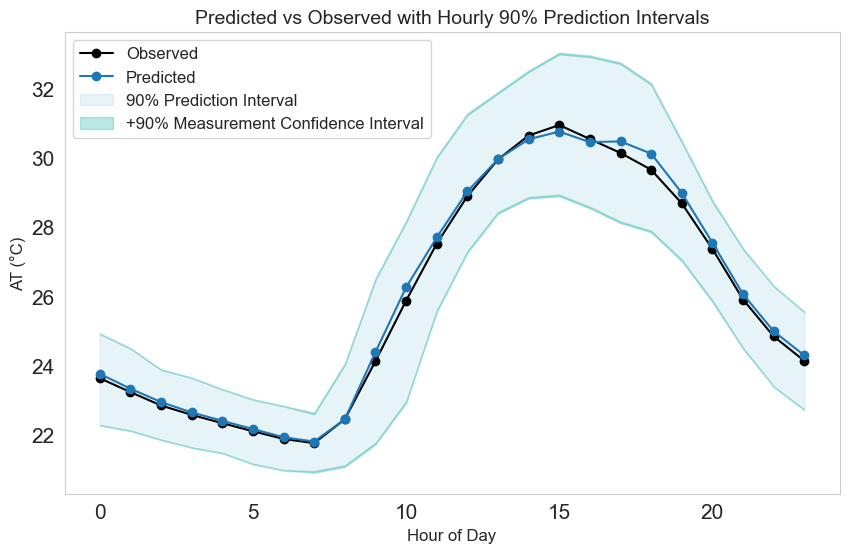

In [73]:
plt.figure(figsize=(10,6))

# Observed mean
plt.plot(hourly_summary['Hour'], hourly_summary['Temperature'],
         marker='o', color='black', label='Observed')

# Predicted mean
plt.plot(hourly_summary['Hour'], hourly_summary['Predicted_Temperature'],
         marker='o', color='tab:blue', label='Predicted')



# Fixed hourly prediction interval band
plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_lower'],
                 hourly_summary['PI_upper'],
                 color='lightblue', alpha=0.3,
                 label='90% Prediction Interval')

plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_upper'],
                 hourly_summary['Measurement_CI_upper'],
                 color='lightseagreen', alpha=0.3,
                 label='+90% Measurement Confidence Interval')

plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['Measurement_CI_lower'],
                 hourly_summary['PI_lower'],
                 color='lightseagreen', alpha=0.3,)
                 #label='+90% Measurement Confidence Interval')

plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('AT (°C)', fontsize=12)
plt.title('Predicted vs Observed with Hourly 90% Prediction Intervals', fontsize=14)
#plt.grid(True, linestyle='--', alpha=0.6)
plt.grid(False)
plt.legend()

plt.tick_params(axis='both', which='both',color='black', )
plt.savefig('results/at_hourly_perf.png',transparent=True)
hourly_summary.to_csv('results/AT_hourly_summary.csv', index = False)

In [126]:
### Prediction intervals based on standard error ####
from scipy.stats import norm
data_all_w_predicted = pd.concat([data_day, data_night])
data_all_w_predicted = data_all_w_predicted[data_all_w_predicted.Sensor_ID.isin(test_sensor_ids)]
# Calculate residuals
data_all_w_predicted['residual'] = data_all_w_predicted['Temperature'] - data_all_w_predicted['Predicted_Temperature']

# Standard error of residuals per hour
hourly_se = (
    data_all_w_predicted.groupby('Hour')['residual']
    .std()
    .reset_index()
    .rename(columns={'residual': 'SE'})
)

# Merge SE back into main DataFrame
data_all_w_predicted = data_all_w_predicted.merge(hourly_se, on='Hour', how='left')

# Define confidence level
#alpha = 0.05   # 95% PI
alpha = 0.1 # 90% PI

z = norm.ppf(1 - alpha/2)   # 1.96 for 95% confidence, 1.645 for 90%

# Compute prediction intervals
data_all_w_predicted['PI_lower'] = data_all_w_predicted['Predicted_Temperature'] - z * data_all_w_predicted['SE']
data_all_w_predicted['PI_upper'] = data_all_w_predicted['Predicted_Temperature'] + z * data_all_w_predicted['SE']


In [128]:
hourly_summary = ( data_all_w_predicted .groupby('Hour')
                  .agg({ 'Temperature': 'mean', 'Predicted_Temperature': 'mean', 'PI_lower': 'mean', 'PI_upper': 'mean' }) 
                  .reset_index() )

In [132]:
(hourly_summary['Temperature']-hourly_summary['PI_lower']).values

array([1.09016946, 1.03761859, 0.9645919 , 0.95734396, 0.92714394,
       0.8919598 , 0.88759259, 0.87014042, 1.35195773, 1.98121401,
       2.01623779, 1.93675456, 1.84457345, 1.78324559, 2.02942572,
       2.23748205, 2.31939772, 1.90991372, 1.6209412 , 1.49485477,
       1.19887732, 1.19124206, 1.18996477, 1.13646878])

In [133]:
(hourly_summary['Temperature']-hourly_summary['PI_upper']).values

array([-1.3414557 , -1.23429013, -1.16104908, -1.09845536, -1.06439924,
       -1.01958845, -0.98540486, -0.96147049, -1.35450905, -2.5026908 ,
       -2.7840661 , -2.29883414, -2.12047926, -1.79925086, -1.81121021,
       -1.86289599, -2.14071645, -2.57613164, -2.55193964, -2.09553443,
       -1.55754425, -1.49302153, -1.48463256, -1.45051767])

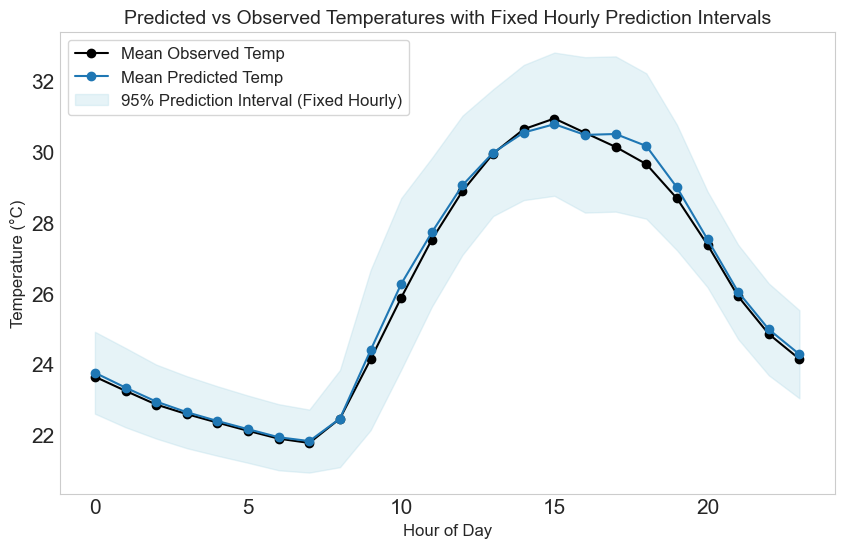

In [20]:
plt.figure(figsize=(10,6))

# Plot mean observed temperature per hour
plt.plot(hourly_summary['Hour'], hourly_summary['Temperature'],
         color='black', marker='o', label='Mean Observed Temp')

# Plot mean predicted temperature per hour
plt.plot(hourly_summary['Hour'], hourly_summary['Predicted_Temperature'],
         color='tab:blue', marker='o', label='Mean Predicted Temp')

# Plot fixed hourly prediction interval as shaded band
plt.fill_between(hourly_summary['Hour'],
                 hourly_summary['PI_lower'],
                 hourly_summary['PI_upper'],
                 color='lightblue', alpha=0.3,
                 label='95% Prediction Interval (Fixed Hourly)')

# Formatting
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.title('Predicted vs Observed Temperatures with Fixed Hourly Prediction Intervals', fontsize=14)
plt.legend()
plt.grid(False)  # remove grid lines
plt.tick_params(axis='both', which='both', length=5, color='black', direction='in')